In [1]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('heart_genetic_disease.csv')

In [3]:
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,FamilyHistory,rs10757274_Genotype,APOE_Genotype,Lpa_Level,FH_Mutation,Genetic_Risk_Score,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0,AG,e2/e3,17.2,0,1.0,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,0,AG,e3/e3,19.5,0,1.0,0
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,1,AA,e3/e4,64.0,0,2.5,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1,AA,e3/e4,64.0,0,2.5,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0,AG,e2/e3,28.4,0,1.0,0


In [4]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'FamilyHistory', 'rs10757274_Genotype', 'APOE_Genotype', 'Lpa_Level',
       'FH_Mutation', 'Genetic_Risk_Score', 'HeartDisease'],
      dtype='str')

In [5]:
df.shape

(918, 18)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  918 non-null    int64  
 1   Sex                  918 non-null    str    
 2   ChestPainType        918 non-null    str    
 3   RestingBP            918 non-null    int64  
 4   Cholesterol          918 non-null    int64  
 5   FastingBS            918 non-null    int64  
 6   RestingECG           918 non-null    str    
 7   MaxHR                918 non-null    int64  
 8   ExerciseAngina       918 non-null    str    
 9   Oldpeak              918 non-null    float64
 10  ST_Slope             918 non-null    str    
 11  FamilyHistory        918 non-null    int64  
 12  rs10757274_Genotype  918 non-null    str    
 13  APOE_Genotype        918 non-null    str    
 14  Lpa_Level            918 non-null    float64
 15  FH_Mutation          918 non-null    int64  
 16  G

In [7]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,FamilyHistory,Lpa_Level,FH_Mutation,Genetic_Risk_Score,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.294118,36.298039,0.032680,1.755991,0.525054
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.455893,42.152982,0.177894,1.107790,0.499644
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,1.400000,0.000000,0.000000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000,12.725000,0.000000,1.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,0.000000,23.200000,0.000000,2.000000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000,44.300000,0.000000,2.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000,436.900000,1.000000,5.500000,1.000000


In [8]:
df.isnull().sum()

Age                    0
Sex                    0
ChestPainType          0
RestingBP              0
Cholesterol            0
FastingBS              0
RestingECG             0
MaxHR                  0
ExerciseAngina         0
Oldpeak                0
ST_Slope               0
FamilyHistory          0
rs10757274_Genotype    0
APOE_Genotype          0
Lpa_Level              0
FH_Mutation            0
Genetic_Risk_Score     0
HeartDisease           0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

<Axes: xlabel='HeartDisease'>

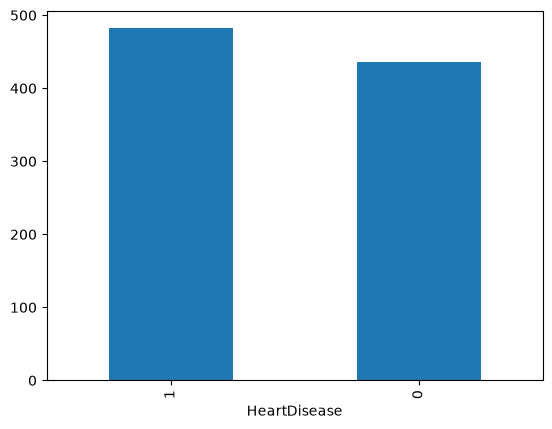

In [10]:
df['HeartDisease'].value_counts().plot(kind='bar')

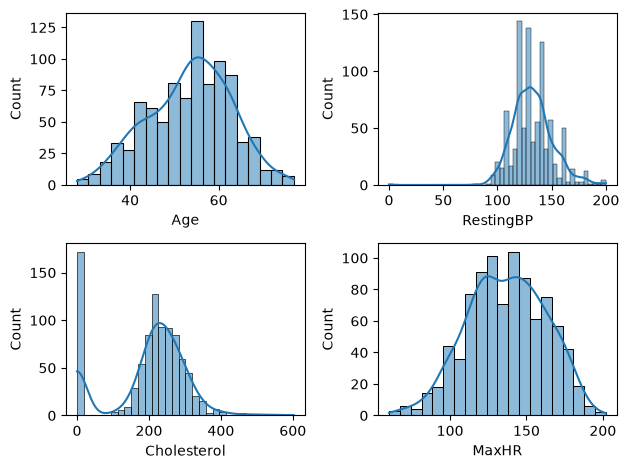

In [11]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)
plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)
plt.tight_layout()

In [12]:
df['Cholesterol'].value_counts()

Cholesterol
0      172
254     11
223     10
220     10
211      9
      ... 
353      1
278      1
157      1
176      1
131      1
Name: count, Length: 222, dtype: int64

In [13]:
ch_mean = df.loc[df['Cholesterol']!=0,'Cholesterol'].mean()

In [14]:
ch_mean

np.float64(244.6353887399464)

In [15]:
df['Cholesterol'] = df['Cholesterol'].replace(0,ch_mean)
df['Cholesterol'] = df['Cholesterol'].round(2)

In [16]:
resting_bp_mean = df.loc[df['RestingBP']!=0,'RestingBP'].mean()

In [17]:
resting_bp_mean

np.float64(132.54089422028352)

In [18]:
df['RestingBP'] = df['RestingBP'].replace(0,resting_bp_mean)
df['RestingBP'] = df['RestingBP'].round(2)

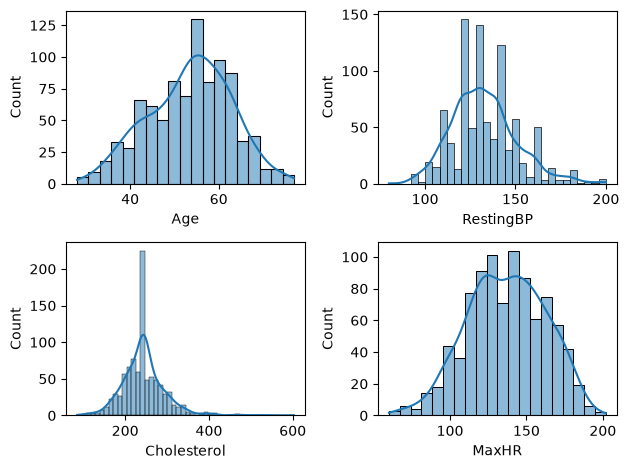

In [19]:
def plotting(var,num):
    plt.subplot(2,2,num)
    sns.histplot(df[var],kde=True)
plotting('Age',1)
plotting('RestingBP',2)
plotting('Cholesterol',3)
plotting('MaxHR',4)
plt.tight_layout()

<Axes: xlabel='Sex', ylabel='count'>

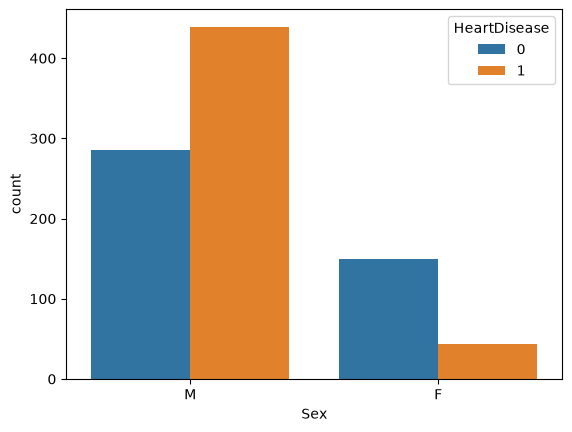

In [20]:
sns.countplot(x=df['Sex'],hue = df['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

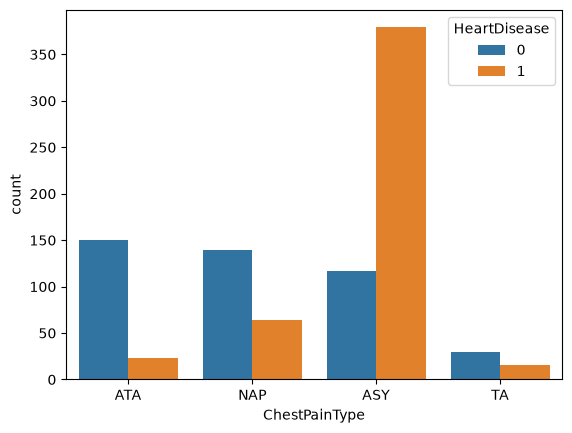

In [21]:
sns.countplot(x = df['ChestPainType'],hue=df['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

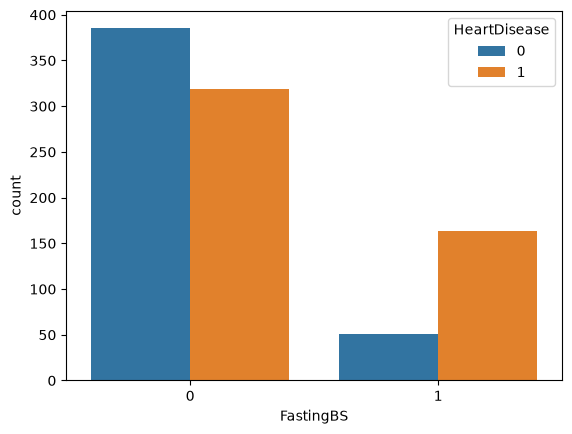

In [22]:
sns.countplot(x = df['FastingBS'],hue=df['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

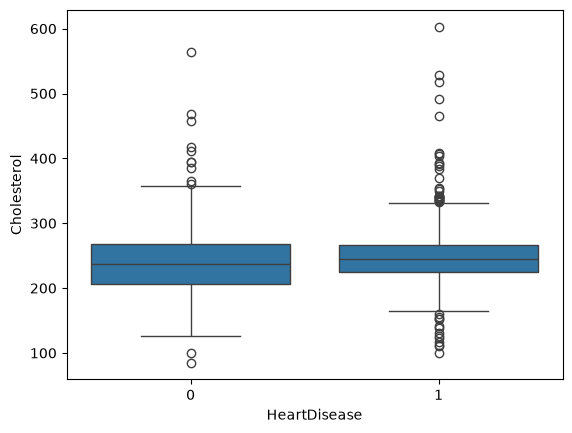

In [23]:
sns.boxplot(x='HeartDisease',y='Cholesterol',data=df)

<Axes: xlabel='HeartDisease', ylabel='Age'>

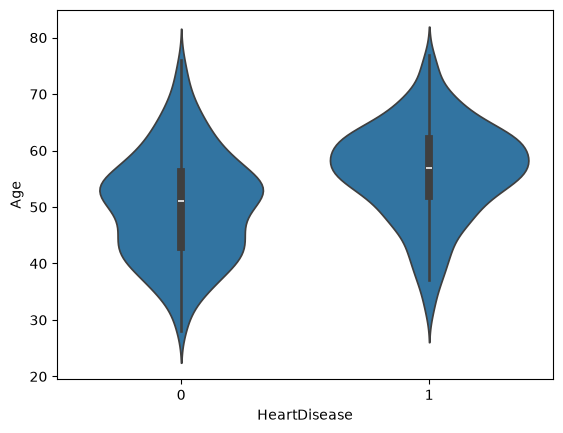

In [24]:
sns.violinplot(x='HeartDisease',y='Age',data=df)

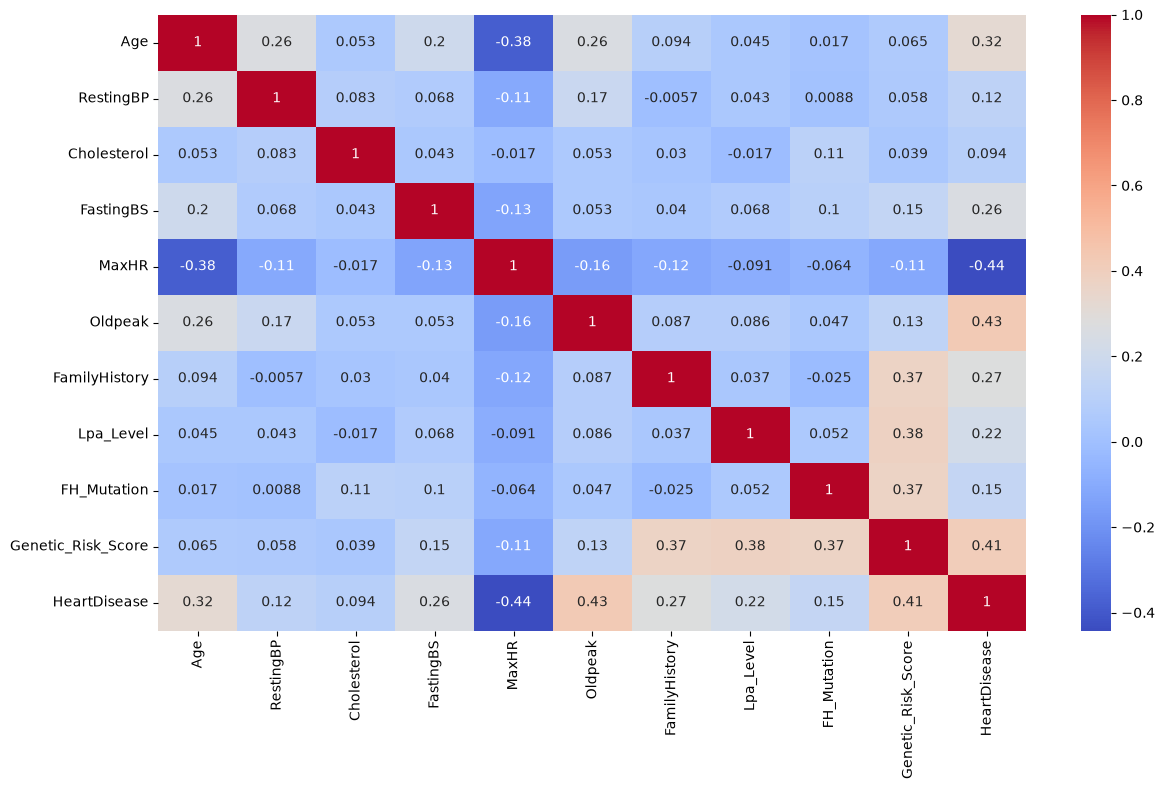

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 8))

sns.heatmap(
    df.corr(numeric_only=True),
    annot=True,
    cmap="coolwarm"
)

plt.show()


## Data Preprocessing and Cleaning

In [26]:
df_encoded = pd.get_dummies(df,drop_first=True)

In [27]:
df_encoded

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,FamilyHistory,Lpa_Level,FH_Mutation,Genetic_Risk_Score,...,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up,rs10757274_Genotype_AG,rs10757274_Genotype_GG,APOE_Genotype_e3/e3,APOE_Genotype_e3/e4,APOE_Genotype_e4/e4
0,40,140.0,289.0,0,172,0.0,0,17.2,0,1.0,...,True,False,False,False,True,True,False,False,False,False
1,49,160.0,180.0,0,156,1.0,0,19.5,0,1.0,...,True,False,False,True,False,True,False,True,False,False
2,37,130.0,283.0,0,98,0.0,1,64.0,0,2.5,...,False,True,False,False,True,False,False,False,True,False
3,48,138.0,214.0,0,108,1.5,1,64.0,0,2.5,...,True,False,True,True,False,False,False,False,True,False
4,54,150.0,195.0,0,122,0.0,0,28.4,0,1.0,...,True,False,False,False,True,True,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,110.0,264.0,0,132,1.2,1,56.0,0,2.0,...,True,False,False,True,False,False,False,False,False,False
914,68,144.0,193.0,1,141,3.4,1,6.2,1,4.0,...,True,False,False,True,False,True,False,True,False,False
915,57,130.0,131.0,0,115,1.2,1,101.6,0,4.5,...,True,False,True,True,False,False,True,False,True,False
916,57,130.0,236.0,0,174,0.0,0,55.0,0,3.5,...,False,False,False,True,False,False,True,False,True,False


In [28]:
df_encoded.columns

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'FamilyHistory', 'Lpa_Level', 'FH_Mutation', 'Genetic_Risk_Score',
       'HeartDisease', 'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP',
       'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST',
       'ExerciseAngina_Y', 'ST_Slope_Flat', 'ST_Slope_Up',
       'rs10757274_Genotype_AG', 'rs10757274_Genotype_GG',
       'APOE_Genotype_e3/e3', 'APOE_Genotype_e3/e4', 'APOE_Genotype_e4/e4'],
      dtype='str')

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

In [30]:
X = df_encoded.drop('HeartDisease',axis=1)
y = df_encoded['HeartDisease']

In [31]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

In [32]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test) 

In [33]:
knn = KNeighborsClassifier()

knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [34]:
manual_data = pd.DataFrame([{
    'Age': 35,
    'RestingBP': 120,
    'Cholesterol': 180,
    'FastingBS': 0,
    'MaxHR': 175,
    'Oldpeak': 0.0,
    'FamilyHistory': 0,
    'Lpa_Level': 0,
    'FH_Mutation': 0,
    'Genetic_Risk_Score': 0,

    'HeartDisease': 0,

    'Sex_M': 0,

    'ChestPainType_ATA': 1,
    'ChestPainType_NAP': 0,
    'ChestPainType_TA': 0,

    'RestingECG_Normal': 1,
    'RestingECG_ST': 0,

    'ExerciseAngina_Y': 0,

    'ST_Slope_Flat': 0,
    'ST_Slope_Up': 1,

    'rs10757274_Genotype_AG': 0,
    'rs10757274_Genotype_GG': 0,

    'APOE_Genotype_e3/e3': 1,
    'APOE_Genotype_e3/e4': 0,
    'APOE_Genotype_e4/e4': 0
}])

# Make sure columns are in exactly the same order as training data
manual_data = manual_data[X.columns]

# Scale the input
manual_scaled = scaler.transform(manual_data)

# Prediction
prediction = knn.predict(manual_scaled)

print("Prediction:", prediction[0])

if prediction[0] == 1:
    print("Heart Disease: YES")
else:
    print("Heart Disease: NO")

Prediction: 0
Heart Disease: NO


In [35]:
models = {
    "Logistic Regression":LogisticRegression(), 
    "KNN":KNeighborsClassifier(), 
    "Native Byeas":GaussianNB(), 
    "Decision tree":DecisionTreeClassifier(), 
    "SVM":SVC(probability=True)
}

In [36]:
results = []

In [37]:
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results.append({
        'Model': name,
        'Accuracy': round(acc, 4),
        'F1 Score': round(f1, 4)
    })

In [38]:
results

[{'Model': 'Logistic Regression', 'Accuracy': 0.8913, 'F1 Score': 0.8925},
 {'Model': 'KNN', 'Accuracy': 0.875, 'F1 Score': 0.8783},
 {'Model': 'Native Byeas', 'Accuracy': 0.8696, 'F1 Score': 0.871},
 {'Model': 'Decision tree', 'Accuracy': 0.75, 'F1 Score': 0.7553},
 {'Model': 'SVM', 'Accuracy': 0.8859, 'F1 Score': 0.8912}]

In [39]:
patient = [[63, 1, 145, 233, 1, 150, 0, 2, 2.3, 0, 0, 1]]

In [40]:
print(model.n_features_in_)

24


In [41]:
print(X_train.columns)

Index(['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak',
       'FamilyHistory', 'Lpa_Level', 'FH_Mutation', 'Genetic_Risk_Score',
       'Sex_M', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA',
       'RestingECG_Normal', 'RestingECG_ST', 'ExerciseAngina_Y',
       'ST_Slope_Flat', 'ST_Slope_Up', 'rs10757274_Genotype_AG',
       'rs10757274_Genotype_GG', 'APOE_Genotype_e3/e3', 'APOE_Genotype_e3/e4',
       'APOE_Genotype_e4/e4'],
      dtype='str')


In [42]:
print(X_train.shape)

(734, 24)


In [43]:
patient = [[63, 1, 145, 233, 1, 150, 0, 2, 2.3, 0, 0, 1]]

In [44]:
import pandas as pd

# Define a single sample with values matching all 24 columns in X_train.columns
sample_data = pd.DataFrame([{
    'Age': 63,
    'RestingBP': 145,
    'Cholesterol': 233,
    'FastingBS': 1,
    'MaxHR': 150,
    'Oldpeak': 2.3,
    'FamilyHistory': 0,
    'Lpa_Level': 2,
    'FH_Mutation': 0,
    'Genetic_Risk_Score': 0,
    'Sex_M': 1,
    'ChestPainType_ATA': 0,
    'ChestPainType_NAP': 0,
    'ChestPainType_TA': 0,
    'RestingECG_Normal': 1,
    'RestingECG_ST': 0,
    'ExerciseAngina_Y': 0,
    'ST_Slope_Flat': 0,
    'ST_Slope_Up': 1,
    'rs10757274_Genotype_AG': 0,
    'rs10757274_Genotype_GG': 0,
    'APOE_Genotype_e3/e3': 1,
    'APOE_Genotype_e3/e4': 0,
    'APOE_Genotype_e4/e4': 0
}])

# Scale using the fitted scaler
sample_scaled = scaler.transform(sample_data)

# Make prediction
prediction = model.predict(sample_scaled)
print("Prediction:", prediction[0])

Prediction: 0


In [45]:
model

,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",True
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [46]:
from sklearn.linear_model import LogisticRegression
import joblib

# Create and train the Logistic Regression model
logistic_model = LogisticRegression(max_iter=1000, random_state=42)

logistic_model.fit(X_train, y_train)

# Evaluate the model
y_pred = logistic_model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

print("Model: Logistic Regression")
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Save the trained model
joblib.dump(logistic_model, "logistic_regression_genetic.pkl")

print("\nLogistic Regression model saved successfully!")

Model: Logistic Regression
Accuracy: 0.8967391304347826

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.96      0.90        84
           1       0.97      0.84      0.90       100

    accuracy                           0.90       184
   macro avg       0.90      0.90      0.90       184
weighted avg       0.91      0.90      0.90       184


Logistic Regression model saved successfully!


## Final Model Training — CardioSense

This section trains and evaluates two Logistic Regression models:
1. Clinical-only model
2. Clinical + Genetic model

Both models use the same train-test split and preprocessing approach.

In [47]:
# ============================================================
# CARDIOSENSE: CLINICAL AND GENETIC MODEL TRAINING
# ============================================================

import pandas as pd
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


# ============================================================
# 1. DEFINE FEATURES
# ============================================================

clinical_features = [
    'Age',
    'Sex',
    'ChestPainType',
    'RestingBP',
    'Cholesterol',
    'FastingBS',
    'RestingECG',
    'MaxHR',
    'ExerciseAngina',
    'Oldpeak',
    'ST_Slope'
]


genetic_features = [
    'FamilyHistory',
    'rs10757274_Genotype',
    'APOE_Genotype',
    'Lpa_Level',
    'FH_Mutation',
    'Genetic_Risk_Score'
]


target = 'HeartDisease'


# Check that all required columns exist
required_columns = clinical_features + genetic_features + [target]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns in dataset: {missing_columns}"
    )


# Separate clinical and genetic feature sets
X_clinical = df[clinical_features].copy()

X_genetic = df[
    clinical_features + genetic_features
].copy()

y = df[target].copy()


# ============================================================
# 2. USE THE SAME TRAIN-TEST SPLIT FOR BOTH MODELS
# ============================================================

X_clinical_train, X_clinical_test, y_train, y_test = (
    train_test_split(
        X_clinical,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)


X_genetic_train, X_genetic_test, _, _ = (
    train_test_split(
        X_genetic,
        y,
        test_size=0.20,
        random_state=42,
        stratify=y
    )
)


# ============================================================
# 3. IDENTIFY NUMERIC AND CATEGORICAL FEATURES
# ============================================================

clinical_numeric = [
    'Age',
    'RestingBP',
    'Cholesterol',
    'FastingBS',
    'MaxHR',
    'Oldpeak'
]

clinical_categorical = [
    'Sex',
    'ChestPainType',
    'RestingECG',
    'ExerciseAngina',
    'ST_Slope'
]

genetic_numeric = [
    'FamilyHistory',
    'Lpa_Level',
    'FH_Mutation',
    'Genetic_Risk_Score'
]

genetic_categorical = [
    'rs10757274_Genotype',
    'APOE_Genotype'
]


# ============================================================
# 4. CREATE PREPROCESSING PIPELINES
# ============================================================

clinical_preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]),
            clinical_numeric
        ),
        (
            'categorical',
            Pipeline(steps=[
                (
                    'imputer',
                    SimpleImputer(strategy='most_frequent')
                ),
                (
                    'encoder',
                    OneHotEncoder(handle_unknown='ignore')
                )
            ]),
            clinical_categorical
        )
    ]
)


genetic_preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            Pipeline(steps=[
                ('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())
            ]),
            clinical_numeric + genetic_numeric
        ),
        (
            'categorical',
            Pipeline(steps=[
                (
                    'imputer',
                    SimpleImputer(strategy='most_frequent')
                ),
                (
                    'encoder',
                    OneHotEncoder(handle_unknown='ignore')
                )
            ]),
            clinical_categorical + genetic_categorical
        )
    ]
)


# ============================================================
# 5. BUILD BOTH LOGISTIC REGRESSION MODELS
# ============================================================

clinical_model = Pipeline(steps=[
    ('preprocessor', clinical_preprocessor),
    (
        'classifier',
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])


genetic_model = Pipeline(steps=[
    ('preprocessor', genetic_preprocessor),
    (
        'classifier',
        LogisticRegression(
            max_iter=2000,
            random_state=42
        )
    )
])


# ============================================================
# 6. TRAIN BOTH MODELS
# ============================================================

clinical_model.fit(
    X_clinical_train,
    y_train
)

genetic_model.fit(
    X_genetic_train,
    y_train
)


print("Both models trained successfully!")


# ============================================================
# 7. EVALUATE BOTH MODELS
# ============================================================

clinical_predictions = clinical_model.predict(
    X_clinical_test
)

genetic_predictions = genetic_model.predict(
    X_genetic_test
)


def evaluate_model(name, y_true, predictions):

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print(
        "Accuracy:",
        round(accuracy_score(y_true, predictions), 4)
    )

    print(
        "Precision:",
        round(
            precision_score(
                y_true,
                predictions,
                zero_division=0
            ),
            4
        )
    )

    print(
        "Recall:",
        round(
            recall_score(
                y_true,
                predictions,
                zero_division=0
            ),
            4
        )
    )

    print(
        "F1 Score:",
        round(
            f1_score(
                y_true,
                predictions,
                zero_division=0
            ),
            4
        )
    )

    print("\nClassification Report:")

    print(
        classification_report(
            y_true,
            predictions,
            zero_division=0
        )
    )

    print("Confusion Matrix:")

    print(
        confusion_matrix(
            y_true,
            predictions
        )
    )


evaluate_model(
    "CLINICAL-ONLY LOGISTIC REGRESSION",
    y_test,
    clinical_predictions
)


evaluate_model(
    "CLINICAL + GENETIC LOGISTIC REGRESSION",
    y_test,
    genetic_predictions
)


# ============================================================
# 8. CREATE A COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame([
    {
        'Model': 'Clinical Only',
        'Accuracy': accuracy_score(
            y_test, clinical_predictions
        ),
        'Precision': precision_score(
            y_test, clinical_predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test, clinical_predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, clinical_predictions, zero_division=0
        )
    },
    {
        'Model': 'Clinical + Genetic',
        'Accuracy': accuracy_score(
            y_test, genetic_predictions
        ),
        'Precision': precision_score(
            y_test, genetic_predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test, genetic_predictions, zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, genetic_predictions, zero_division=0
        )
    }
])


print("\nMODEL COMPARISON")
display(
    comparison.round(4)
)


# ============================================================
# 9. SAVE COMPLETE PIPELINES
# ============================================================

joblib.dump(
    clinical_model,
    'clinical_model.pkl'
)

joblib.dump(
    genetic_model,
    'genetic_model.pkl'
)


print("\nBoth models saved successfully!")
print("1. clinical_model.pkl")
print("2. genetic_model.pkl")

Both models trained successfully!

CLINICAL-ONLY LOGISTIC REGRESSION
Accuracy: 0.8587
Precision: 0.866
Recall: 0.866
F1 Score: 0.866

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.85      0.85        87
           1       0.87      0.87      0.87        97

    accuracy                           0.86       184
   macro avg       0.86      0.86      0.86       184
weighted avg       0.86      0.86      0.86       184

Confusion Matrix:
[[74 13]
 [13 84]]

CLINICAL + GENETIC LOGISTIC REGRESSION
Accuracy: 0.8913
Precision: 0.9231
Recall: 0.866
F1 Score: 0.8936

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.92      0.89        87
           1       0.92      0.87      0.89        97

    accuracy                           0.89       184
   macro avg       0.89      0.89      0.89       184
weighted avg       0.89      0.89      0.89       184

Confusion Matrix:
[[80

,Model,Accuracy,Precision,Recall,F1 Score
0,Clinical Only,0.8587,0.8660,0.866,0.8660
1,Clinical + Genetic,0.8913,0.9231,0.866,0.8936



Both models saved successfully!
1. clinical_model.pkl
2. genetic_model.pkl


In [48]:
genetic_columns = [
    "FamilyHistory",
    "rs10757274_Genotype",
    "APOE_Genotype",
    "Lpa_Level",
    "FH_Mutation",
    "Genetic_Risk_Score"
]

for col in genetic_columns:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(20))


FamilyHistory
FamilyHistory
0    648
1    270
Name: count, dtype: int64

rs10757274_Genotype
rs10757274_Genotype
AG    444
AA    239
GG    235
Name: count, dtype: int64

APOE_Genotype
APOE_Genotype
e3/e3    537
e3/e4    228
e2/e3     94
e4/e4     59
Name: count, dtype: int64

Lpa_Level
Lpa_Level
8.0     8
10.0    7
8.4     6
7.3     6
8.7     6
9.9     6
17.5    6
14.1    6
19.5    5
5.6     5
5.5     5
25.7    5
14.4    5
11.2    5
15.5    5
9.0     5
12.7    5
17.2    4
25.9    4
6.7     4
Name: count, dtype: int64

FH_Mutation
FH_Mutation
0    888
1     30
Name: count, dtype: int64

Genetic_Risk_Score
Genetic_Risk_Score
1.0    263
2.0    203
0.0     92
3.0     91
2.5     85
1.5     68
4.0     36
3.5     34
0.5     30
4.5      8
5.0      5
5.5      3
Name: count, dtype: int64
